<a href="https://colab.research.google.com/github/Arun-0807/Crypto_currency-prdeiction/blob/main/Crypto_currency_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print("Column names:", df.columns.tolist())

Saving coin_Aave.csv to coin_Aave.csv
Dataset loaded successfully!
Dataset shape: (275, 10)


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Aave,AAVE,2020-10-05 23:59:59,55.112358,49.787900,52.675035,53.219243,0.000000e+00,8.912813e+07
1,2,Aave,AAVE,2020-10-06 23:59:59,53.402270,40.734578,53.291969,42.401599,5.830915e+05,7.101144e+07
2,3,Aave,AAVE,2020-10-07 23:59:59,42.408314,35.970690,42.399947,40.083976,6.828342e+05,6.713004e+07
3,4,Aave,AAVE,2020-10-08 23:59:59,44.902511,36.696057,39.885262,43.764463,1.658817e+06,2.202651e+08
4,5,Aave,AAVE,2020-10-09 23:59:59,47.569533,43.291776,43.764463,46.817744,8.155377e+05,2.356322e+08


Column names: ['SNo', 'Name', 'Symbol', 'Date', 'High', 'Low', 'Open', 'Close', 'Volume', 'Marketcap']


In [3]:
# Clean column names
df.columns = df.columns.str.strip()

# Find the date column
date_candidates = ["date", "datetime", "timestamp"]
date_col = next(
    (c for c in df.columns if c.lower() in date_candidates),
    None
)

if date_col is None:
    raise ValueError("No Date column found. Check your dataset columns.")

# Find the closing-price column
close_col = next(
    (c for c in df.columns
     if c.lower().replace("_", " ").strip()
     in ["close", "closing price", "close price", "adj close"]),
    None
)

if close_col is None:
    raise ValueError("No closing-price column found.")

# Filter Bitcoin if the file contains multiple cryptocurrencies
coin_col = next(
    (c for c in df.columns
     if c.lower() in ["symbol", "coin", "crypto", "cryptocurrency", "name"]),
    None
)

if coin_col is not None:
    coin_values = df[coin_col].astype(str).str.strip().str.lower()
    bitcoin_mask = coin_values.isin(
        ["btc", "bitcoin", "bitcoin (btc)", "btc-usd", "btc/usd"]
    )

    if bitcoin_mask.any():
        df = df[bitcoin_mask].copy()

# Convert date and sort chronologically
df[date_col] = pd.to_datetime(df[date_col], errors="coerce", utc=True)
df = df.dropna(subset=[date_col])
df = df.sort_values(date_col)
df = df.drop_duplicates(subset=[date_col], keep="last")

# Use common market features when available
preferred_features = [
    "open", "high", "low", "close", "volume"
]

feature_cols = [
    c for feature in preferred_features
    for c in df.columns
    if c.lower().replace("_", " ").strip() == feature
]

# Ensure the closing-price column is included
if close_col not in feature_cols:
    feature_cols.append(close_col)

# Convert market features to numeric values
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep valid closing prices and handle missing feature values
df = df.dropna(subset=[close_col]).copy()
df[feature_cols] = df[feature_cols].ffill()
df = df.dropna(subset=feature_cols)

# Keep approximately 2,000 consecutive daily records
df = df.drop_duplicates(subset=[date_col]).tail(2000).copy()
df = df.reset_index(drop=True)

if len(df) < 100:
    raise ValueError("Too few valid records. Check your dataset.")

print("Date column:", date_col)
print("Closing-price column:", close_col)
print("Features:", feature_cols)
print("Number of records:", len(df))
print("Start date:", df[date_col].min())
print("End date:", df[date_col].max())

display(df[[date_col] + feature_cols].head())

Date column: Date
Closing-price column: Close
Features: ['Open', 'High', 'Low', 'Close', 'Volume']
Number of records: 275
Start date: 2020-10-05 23:59:59+00:00
End date: 2021-07-06 23:59:59+00:00


,Date,Open,High,Low,Close,Volume
0,2020-10-05 23:59:59+00:00,52.675035,55.112358,49.787900,53.219243,0.000000e+00
1,2020-10-06 23:59:59+00:00,53.291969,53.402270,40.734578,42.401599,5.830915e+05
2,2020-10-07 23:59:59+00:00,42.399947,42.408314,35.970690,40.083976,6.828342e+05
3,2020-10-08 23:59:59+00:00,39.885262,44.902511,36.696057,43.764463,1.658817e+06
4,2020-10-09 23:59:59+00:00,43.764463,47.569533,43.291776,46.817744,8.155377e+05


Missing values before final cleaning:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


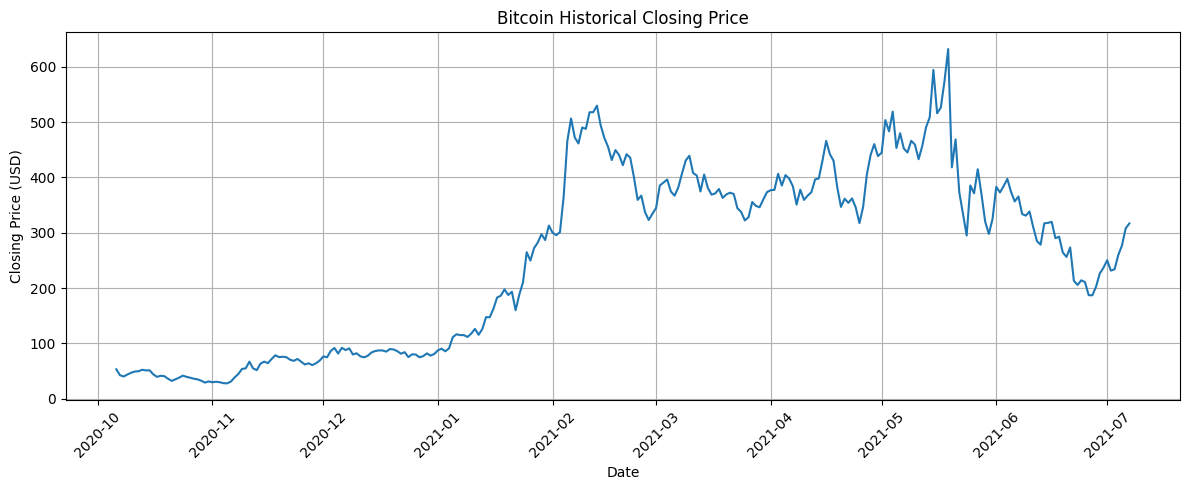

In [4]:
print("Missing values before final cleaning:")
print(df[feature_cols].isnull().sum())

plt.figure(figsize=(12, 5))
plt.plot(df[date_col], df[close_col])
plt.title("Bitcoin Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
# Chronological 80:20 split
split_index = int(len(df) * 0.80)

# Scale input features
feature_scaler = MinMaxScaler()

feature_scaler.fit(df[feature_cols].iloc[:split_index])

scaled_features = feature_scaler.transform(df[feature_cols])

# Scale the target closing price separately
target_scaler = MinMaxScaler()

target_scaler.fit(
    df[[close_col]].iloc[:split_index]
)

scaled_close = target_scaler.transform(df[[close_col]])

print("Training records:", split_index)
print("Remaining test records:", len(df) - split_index)
print("Normalized feature shape:", scaled_features.shape)

Training records: 220
Remaining test records: 55
Normalized feature shape: (275, 5)


In [6]:
window_size = 7

X = []
y = []
target_indices = []

for i in range(window_size, len(df)):
    # Previous 7 days of numerical features
    X.append(scaled_features[i - window_size:i])

    # Closing price for the next day
    y.append(scaled_close[i, 0])

    # Save the row index for chronological splitting
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# Split according to the target day's position
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (213, 7, 5)
y_train shape: (213,)
X_test shape: (55, 7, 5)
y_test shape: (55,)


In [7]:
model = Sequential([
    LSTM(50, input_shape=(window_size, len(feature_cols))),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        11,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,501 (48.83 KB)

 Trainable params: 12,501 (48.83 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0636 - val_loss: 0.0884
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0073 - val_loss: 0.0075
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0216 - val_loss: 0.0125
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0093 - val_loss: 0.0133
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0096 - val_loss: 0.0289
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0094 - val_loss: 0.0195
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0073 - val_loss: 0.0085
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0077 - val_loss: 0.0075
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0062 - val_loss: 0.0125
Model training completed!


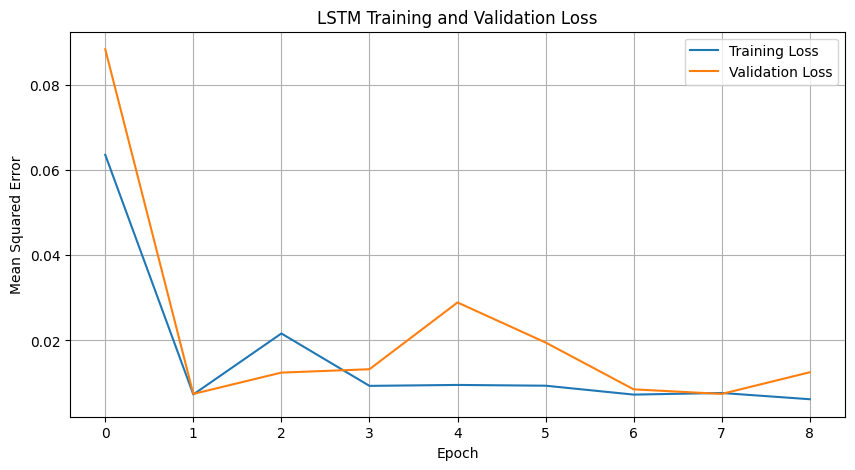

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Predict unseen test sequences
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized prices to original prices
y_pred = target_scaler.inverse_transform(
    y_pred_scaled
).flatten()

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

print("Test MAE:", round(mae, 2))
print("Test RMSE:", round(rmse, 2))

Test MAE: 52.55
Test RMSE: 68.33


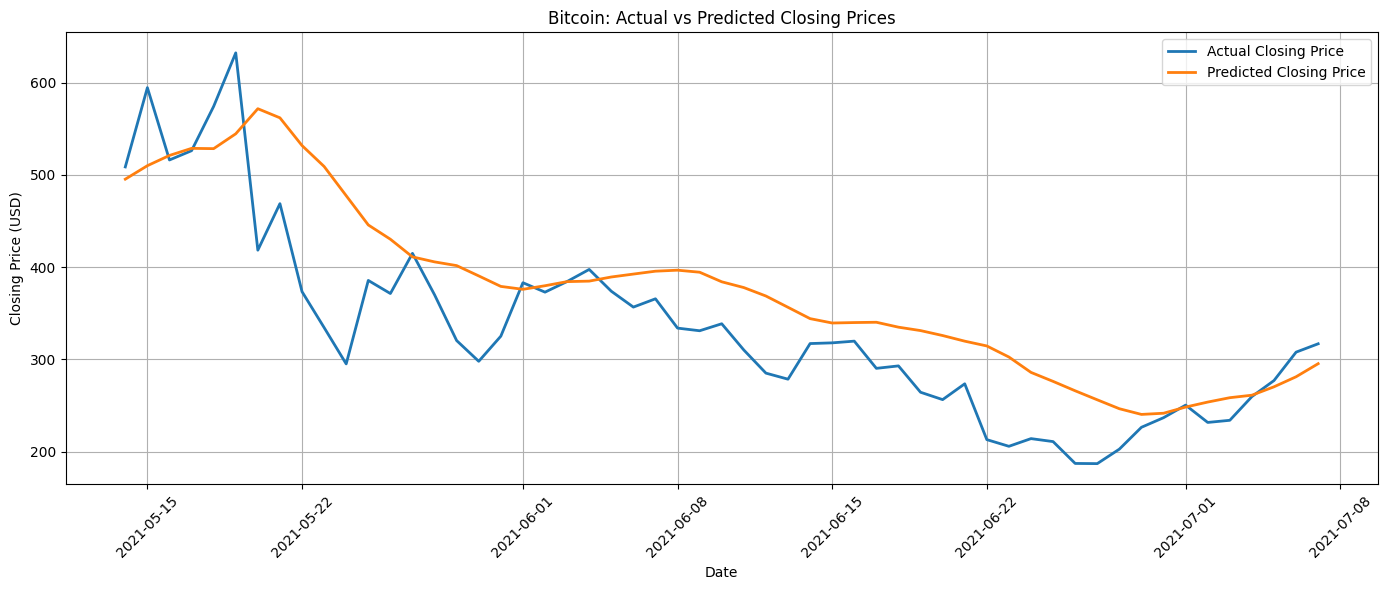

In [11]:
test_dates = df[date_col].iloc[target_indices[test_mask]]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_actual,
    label="Actual Closing Price",
    linewidth=2
)

plt.plot(
    test_dates,
    y_pred,
    label="Predicted Closing Price",
    linewidth=2
)

plt.title("Bitcoin: Actual vs Predicted Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
results = pd.DataFrame({
    "Date": test_dates.reset_index(drop=True),
    "Actual Close": y_actual,
    "Predicted Close": y_pred
})

results["Absolute Error"] = abs(
    results["Actual Close"] - results["Predicted Close"]
)

display(results.head(15).round(2))

,Date,Actual Close,Predicted Close,Absolute Error
0,2021-05-13 23:59:59+00:00,508.62,495.350006,13.27
1,2021-05-14 23:59:59+00:00,594.56,509.950012,84.61
2,2021-05-15 23:59:59+00:00,516.17,521.070007,4.90
3,2021-05-16 23:59:59+00:00,526.21,528.750000,2.53
4,2021-05-17 23:59:59+00:00,574.26,528.440002,45.82
5,2021-05-18 23:59:59+00:00,632.27,544.530029,87.73
6,2021-05-19 23:59:59+00:00,418.37,571.729980,153.36
7,2021-05-20 23:59:59+00:00,468.81,561.849976,93.04
8,2021-05-21 23:59:59+00:00,373.42,531.799988,158.38
9,2021-05-22 23:59:59+00:00,334.48,509.119995,174.64


In [13]:
last_7_days = scaled_features[-window_size:]

# Add the batch dimension
last_7_days = last_7_days.reshape(
    1, window_size, len(feature_cols)
)

next_day_scaled = model.predict(
    last_7_days, verbose=0
)

next_day_price = target_scaler.inverse_transform(
    next_day_scaled
)[0, 0]

last_date = df[date_col].iloc[-1]
next_date = last_date + pd.Timedelta(days=1)

print("Last available date:", last_date.date())
print("Forecast date:", next_date.date())
print(
    "Predicted next-day closing price:",
    round(float(next_day_price), 2)
)

Last available date: 2021-07-06
Forecast date: 2021-07-07
Predicted next-day closing price: 312.22


In [14]:
print("Last 7 days used for prediction:")

display(
    df[[date_col] + feature_cols].tail(7)
)

print("Predicted next-day closing price:",
      round(float(next_day_price), 2))

Last 7 days used for prediction:


,Date,Open,High,Low,Close,Volume
268,2021-06-30 23:59:59+00:00,238.119127,252.121116,220.081412,250.385494,3.636699e+08
269,2021-07-01 23:59:59+00:00,250.710438,251.974412,227.691419,231.626362,3.307151e+08
270,2021-07-02 23:59:59+00:00,230.814119,234.483957,215.951539,233.948437,2.566395e+08
271,2021-07-03 23:59:59+00:00,234.208478,265.107342,228.485206,259.655225,3.853778e+08
272,2021-07-04 23:59:59+00:00,259.399426,289.001124,248.285491,277.038792,4.275719e+08
273,2021-07-05 23:59:59+00:00,277.110533,317.387234,263.433881,307.829079,7.931409e+08
274,2021-07-06 23:59:59+00:00,307.997525,346.714780,307.997525,316.898507,9.887055e+08


Predicted next-day closing price: 312.22
